# 29 — Duas janelas semanais para compras e preparo

A cada sexta-feira, estimar cada almoço da semana posterior (10–14 dias) sem reservas futuras e atualizar o plano da semana imediatamente seguinte (3–7 dias) com o quantitativo institucional. A regra curta permanece 25% modelo +75% institucional +10 refeições.

**Estado:** teste retrospectivo de desenvolvimento. 2026 é diagnóstico já examinado; a melhora do combinado não constitui confirmação independente. Cardápio antecipado e recebimento histórico de consumos têm disponibilidade assumida, não documentalmente comprovada. A decisão pertence à gestão.

Este notebook depende dos scripts e dados do acervo local. O repositório público contém os notebooks; os dados, scripts de apoio, modelos e dissertações não integram esta publicação.

## Protocolo e execução

Construir atributos com corte em cada sexta, sem consumos da semana intermediária; ajustar pré-processamento no treino. ExtraTrees, Ridge residual e mediana sazonal são comparados em 2024. Conferir regras fixas em 2025 e diagnosticar 2026 sem seus alvos no ajuste. As margens próprias da saída longa usam erros temporais anteriores à origem. 2:1 e 9:1 são prioridades hipotéticas de déficit, não preços ou penalidades.

In [1]:
from pathlib import Path
import subprocess, sys, os, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path(os.environ.get("PRODUTO_MESTRADO_ROOT", r"F:\PRODUTO_MESTRADO"))
OUT = ROOT / "resultados/previsao_antecipada_compras/experimento_20261003"
env = dict(os.environ, PYTHONIOENCODING="utf-8", PYTHONDONTWRITEBYTECODE="1")
result = subprocess.run([sys.executable, str(ROOT/"scripts/testar_duas_janelas_semanais.py")], cwd=ROOT, env=env, capture_output=True, text=True, encoding="utf-8")
print(result.stdout)
if result.returncode:
    raise RuntimeError(result.stderr)
rules = json.loads((OUT/"regras_selecionadas.json").read_text(encoding="utf-8"))
display(rules)

Experimento preservado; hashes conferidos.
 ano                        metodo  n_datas  MAE_refeicoes  WAPE_pct  vies_refeicoes  excesso_potencial  deficit_potencial  dias_deficit  dias_sem_deficit_pct  perda_2a1  perda_9a1
2023                  Compras puro      105          33.49     32.61           12.69             2424.0             1092.0            46                 56.19      43.89     116.69
2024                  Compras puro      122          33.30     19.91          -15.93             1060.0             3003.0            78                 36.07      57.92     230.22
2025                  Compras puro      155          24.01     17.35            8.59             2526.0             1195.0            63                 59.35      31.72      85.68
2026                  Compras puro      123          33.41     19.98           -5.01             1747.0             2363.0            80                 34.96      52.63     187.11
2023              Compras moderado      105         

{'modelo': 'Ridge residual 10–14',
 'moderado': 'Fixa +10',
 'conservador': 'P90 global',
 'selecao_ano': 2024,
 'politica_preparo': 'ceil(0.25*previsao_sem_reservas + 0.75*quantitativo +10)'}

## Comparação pareada

Todas as estratégias abaixo usam as mesmas refeições dentro de cada ano. A referência institucional é recebida uma semana depois da origem da previsão longa. O modelo puro e o plano após margem são avaliados separadamente. As novas coortes não substituem as de 390, 397 ou 123 datas anteriores.

In [2]:
scores = pd.read_csv(OUT/"metricas_coorte_pareada.csv")
display(scores.loc[scores.ano.isin([2025, 2026])].round(2))
display(pd.read_csv(OUT/"intervalos_diferencas_MAE.csv").round(2))

,ano,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,dias_sem_deficit_pct,perda_2a1,perda_9a1
2,2025,Compras puro,155,24.01,17.35,8.59,2526.0,1195.0,63,59.35,31.72,85.68
3,2026,Compras puro,123,33.41,19.98,-5.01,1747.0,2363.0,80,34.96,52.63,187.11
6,2025,Compras moderado,155,27.40,19.80,18.59,3564.0,683.0,40,74.19,31.81,62.65
7,2026,Compras moderado,123,31.97,19.12,4.99,2273.0,1659.0,63,48.78,45.46,139.87
10,2025,Compras conservador,155,62.04,44.83,61.61,9583.0,33.0,2,98.71,62.25,63.74
11,2026,Compras conservador,123,44.95,26.88,40.35,5246.0,283.0,16,86.99,47.25,63.36
14,2025,Referência sazonal antecipada,155,20.04,14.48,3.10,1793.0,1313.0,68,56.13,28.51,87.81
15,2026,Referência sazonal antecipada,123,41.95,25.09,-11.72,1859.0,3301.0,81,34.15,68.79,256.65
18,2025,Controle semanal transferido,155,20.98,15.16,4.62,1984.0,1268.0,71,54.19,29.16,86.43
19,2026,Controle semanal transferido,123,38.13,22.80,-16.15,1352.0,3338.0,90,26.83,65.27,255.24


,ano,metodo,referencia,delta_MAE,IC95_inferior,IC95_superior,n_semanas,interpretacao
0,2025,Compras puro,Referência sazonal antecipada,3.97,0.84,7.49,36,negativo favorece o método; intervalo descriti...
1,2025,Compras moderado,Quantitativo institucional,-1.39,-8.36,7.18,36,negativo favorece o método; intervalo descriti...
2,2025,Preparo combinado +10,Quantitativo institucional,-8.01,-10.88,-4.65,36,negativo favorece o método; intervalo descriti...
3,2026,Compras puro,Referência sazonal antecipada,-8.54,-15.63,-1.61,29,negativo favorece o método; intervalo descriti...
4,2026,Compras moderado,Quantitativo institucional,5.76,-2.25,13.82,29,negativo favorece o método; intervalo descriti...
5,2026,Preparo combinado +10,Quantitativo institucional,-1.55,-3.50,0.78,29,negativo favorece o método; intervalo descriti...


## Representações para a dissertação

A figura de erro compara qualidade dos planos. A figura de risco separa excesso e déficit potenciais. Os rótulos estão em português e as imagens não têm título interno. Déficit potencial não mede refeições efetivamente não atendidas; excesso potencial não mede desperdício físico.

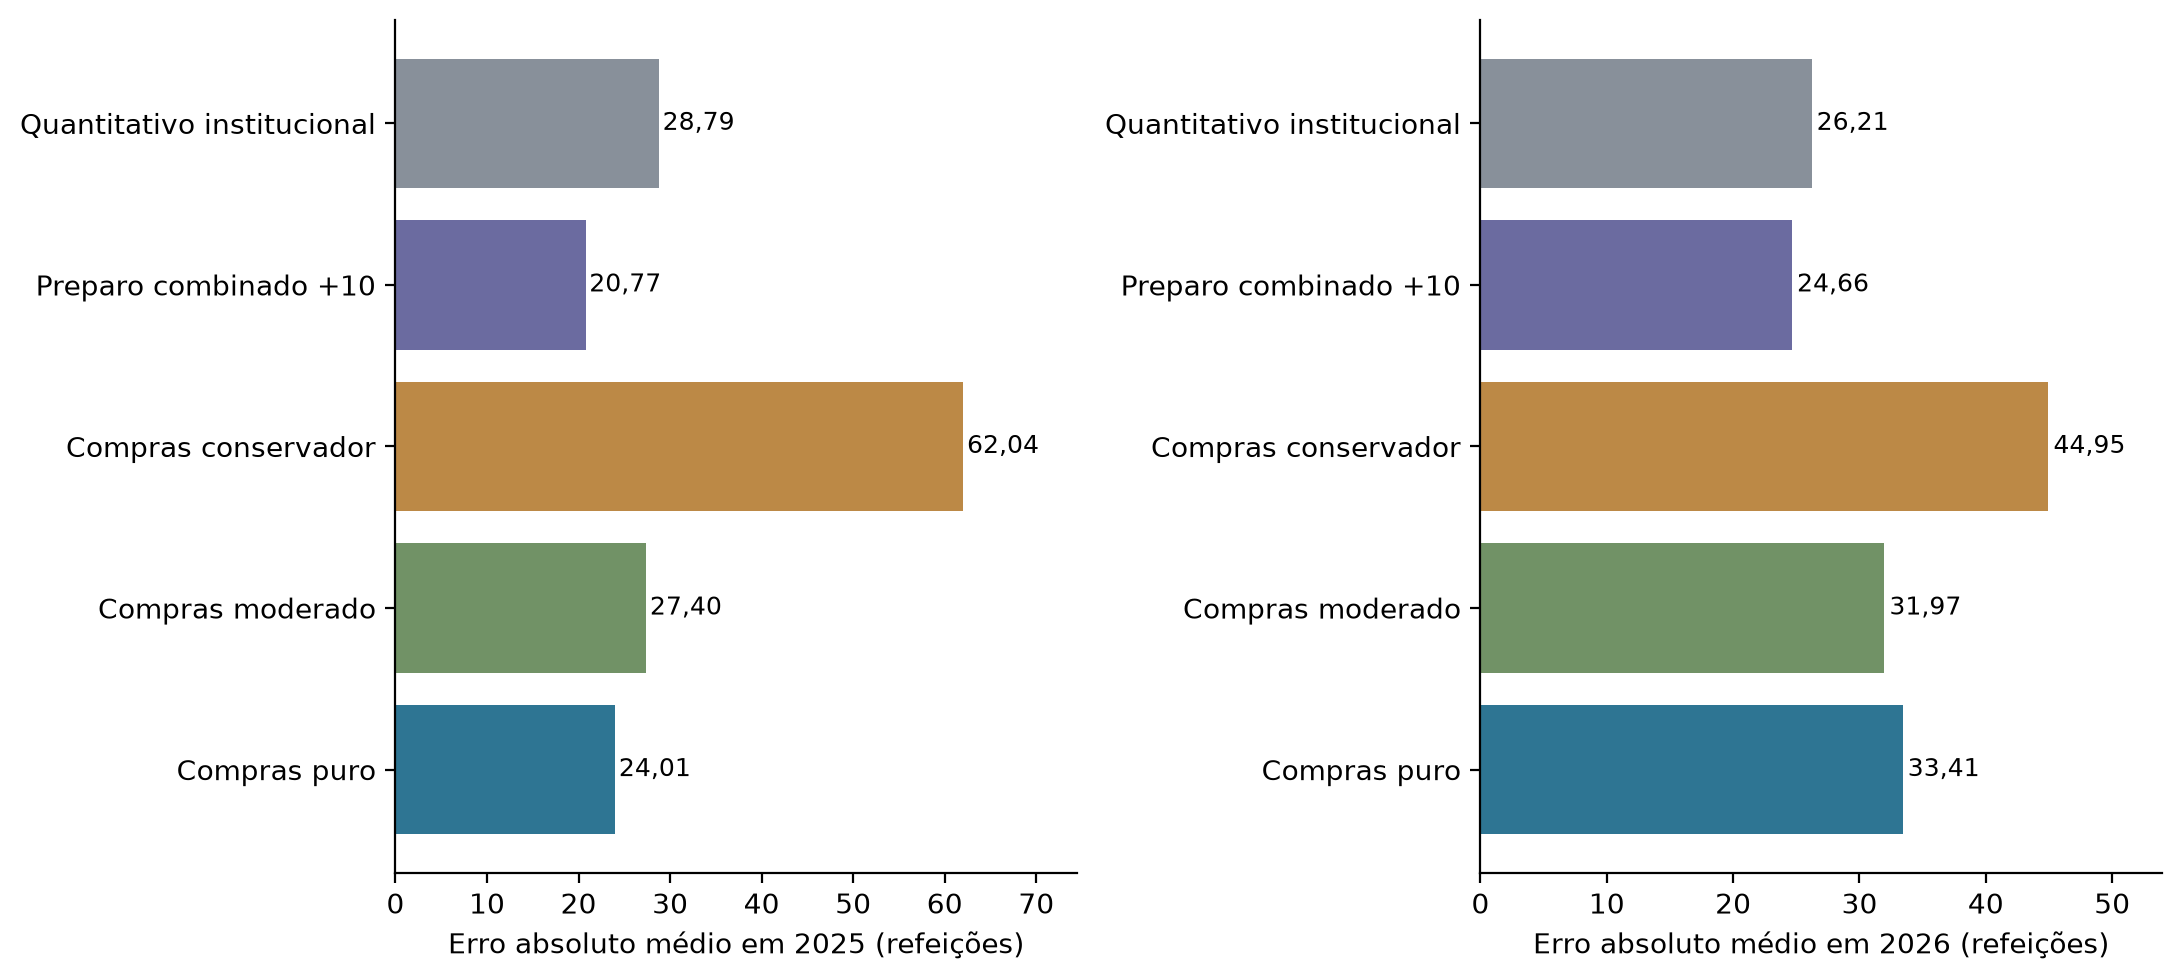

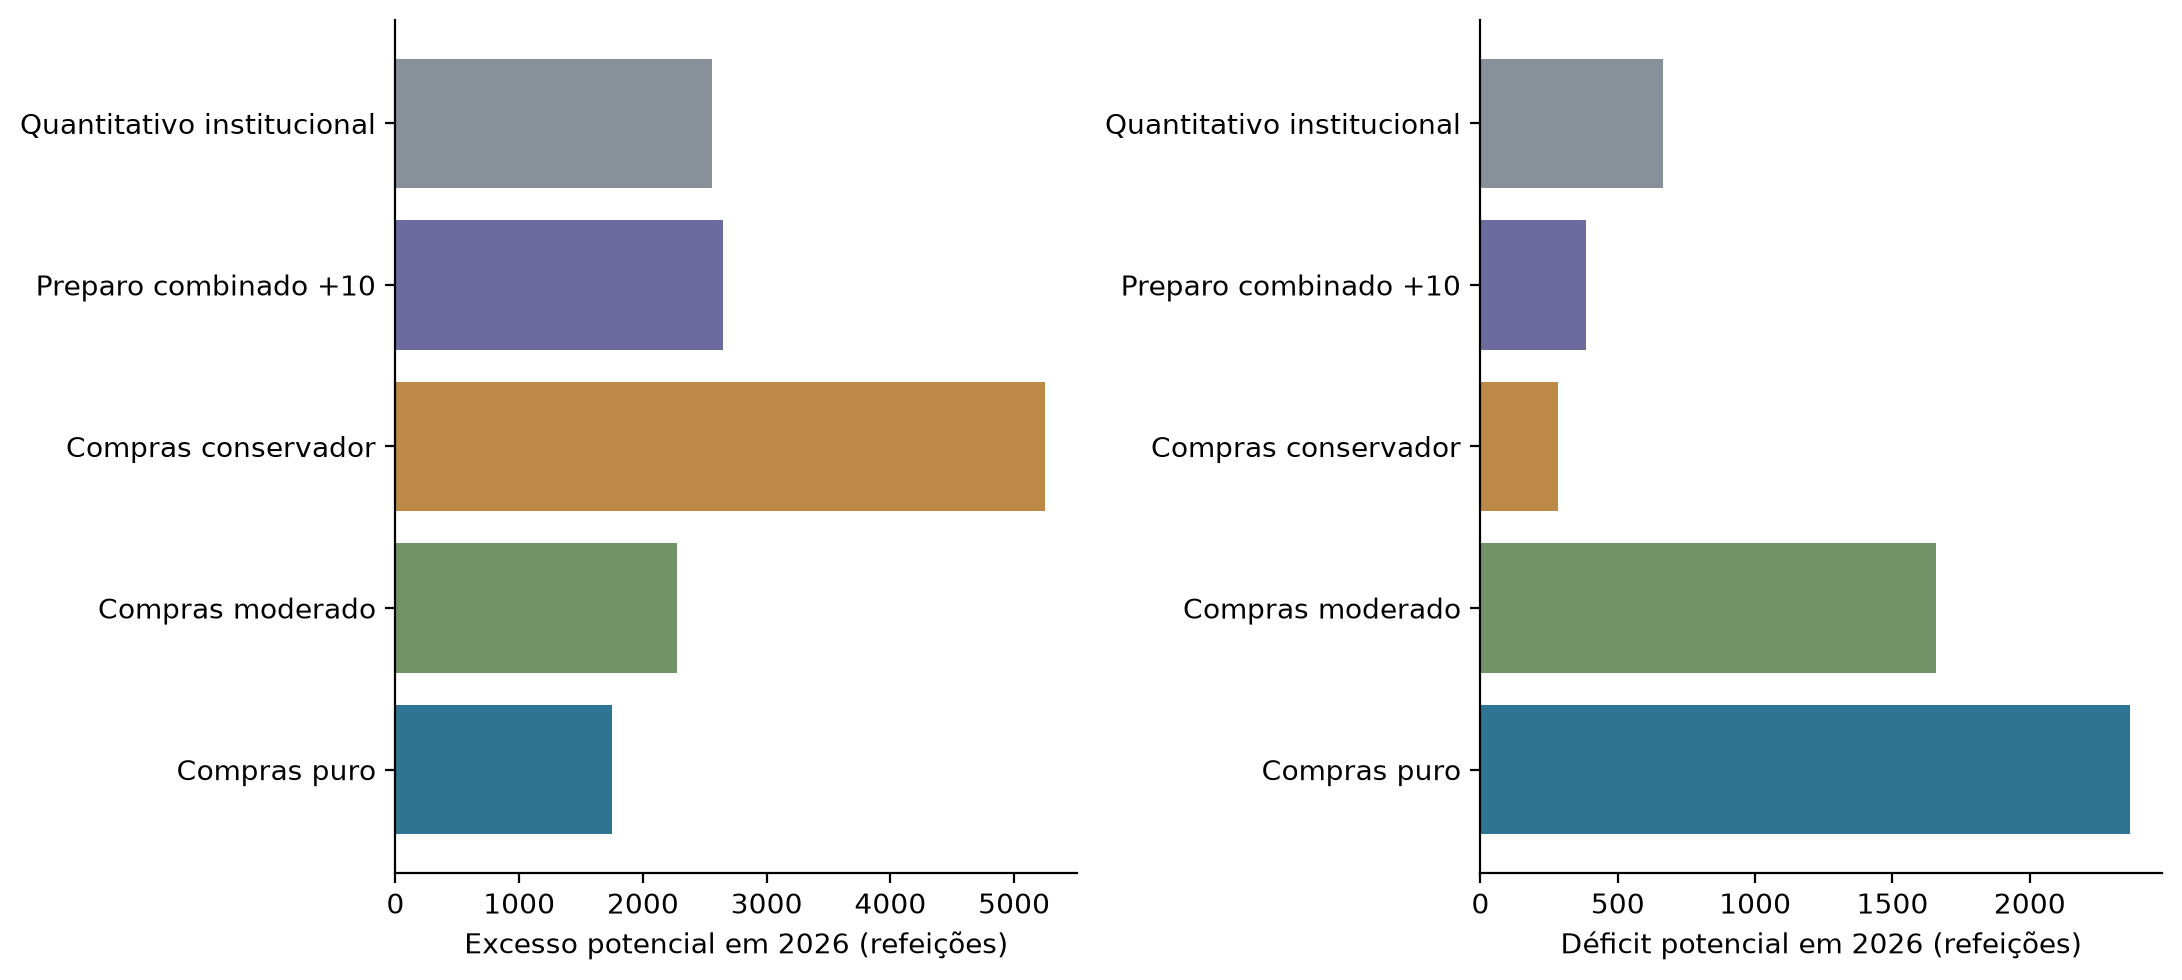

In [3]:
display(Image(filename=str(OUT/"figuras/erro_duas_janelas.png")))
display(Image(filename=str(OUT/"figuras/risco_duas_janelas.png")))

## Auditoria e agenda

A auditoria modifica consumos e reservas posteriores ao corte e exige atributos invariantes. O treino de 2026 continua em 2023–2025 e suas margens não usam consumos de 2026. A agenda é planejamento de emissões: não representa previsões emitidas em sextas futuras. Recesso 12–16/10: sem almoço. Sábados 24 e 31/10: sem almoço.

In [4]:
checks = json.loads((OUT/"checagens.json").read_text(encoding="utf-8"))
display({k:v for k,v in checks.items() if k != "arquivos_anteriores_preservados"})
agenda = pd.read_csv(OUT/"agenda_emissoes_outubro.csv")
display(agenda.groupby(["sexta_planejada", "janela"])["almoço_previsto"].sum().rename("dias_com_almoço"))
assert checks["invariancia_consumos_e_reservas_posteriores"]
assert not checks["alvos_2026_na_selecao_ou_margens"]
assert checks["politica_curta_preservada"]

{'finalizado_em': '2026-10-03T22:52:04.602508-03:00',
 'n_origens_auditadas': 130,
 'reparos_execucao': ['Ridge exclui aquecimento sem referência residual; nenhum alvo imputado',
  'Invariância compara valores; concatenação transforma StringDtype em object sem mudar conteúdo'],
 'invariancia_consumos_e_reservas_posteriores': True,
 'treino_2026_ajusta_estimadores': False,
 'alvos_2026_na_selecao_ou_margens': False,
 'datas_pareadas': True,
 'cardapio_antecipado_comprovado': False,
 'consumo_recebimento_historico_comprovado': False,
 'modelos_e_margens_selecionados_2024': True,
 'politica_curta_preservada': True,
 'emissoes_prospectivas_novas': 0,
 'nenhuma_origem_futura_executada': True,
 'coortes': {'2023': 105, '2024': 122, '2025': 155, '2026': 123}}

sexta_planejada  janela 
2026-10-02       Compras    0
                 Preparo    5
2026-10-09       Compras    5
                 Preparo    0
2026-10-16       Compras    5
                 Preparo    5
2026-10-23       Compras    4
                 Preparo    5
2026-10-30       Compras    5
                 Preparo    4
Name: dias_com_almoço, dtype: int64

## Regra selecionada e acompanhamento

Modelo longo: **Ridge residual 10–14**. Moderado: **Fixa +10**. Conservador: **P90 global**. A margem conservadora é pelo menos a moderada. Percentis nominais não garantem cobertura futura.

Preservar a estimativa de compras e registrar a atualização da mesma semana em outra versão, quando o quantitativo institucional chegar. Não escolher o plano depois de ver o consumo e tratá-lo como previsão anterior. A gestora confirmou a pertinência das duas saídas: compras antecipadas e preparo/descongelamento após o ajuste. Prazos por insumo e tolerância a erro ainda precisam de definição. A nutricionista informou disponibilidade usual do cardápio do mês seguinte com um mês de antecedência; a entrega de cada versão será registrada. Um resultado favorável retrospectivo não demonstra economia ou adoção operacional.

Nas duas janelas conservar previsão pura e cenários moderado/conservador, calibrados nos erros próprios de cada modelo/horizonte. O combinado +10 do preparo é apresentado separadamente.

## Rotina confirmada com a gestão e rastreabilidade

Fonte: relato do pesquisador em 03/10/2026 após conversar com a gestora e a nutricionista, sem atribuir entrevista formal ou avaliação operacional já concluída. Na sexta t, estimar os almoços a 10–14 dias para compras. Na sexta t+7, recalcular a previsão para as mesmas datas a 3–7 dias, considerando apenas consumos recebidos e anteriores ao corte, e combinar com o quantitativo institucional. Preservar a emissão antecipada, a nova emissão, os atributos, fontes, recebimentos e hashes.

A consulta sustenta a pertinência à rotina; não demonstra economia ou superioridade. Emissão após a sexta informa antecedência real e nominal. Datas futuras da agenda não são execuções já realizadas.

In [5]:
result = subprocess.run([sys.executable, str(ROOT/"scripts/rotina_duas_janelas.py")], cwd=ROOT, env=env, capture_output=True, text=True, encoding="utf-8")
print(result.stdout)
if result.returncode:
    raise RuntimeError(result.stderr)
ROTINA = ROOT/"resultados/previsao_antecipada_compras/rotina_20261003"
display(pd.read_csv(ROTINA/"quadro_comparativo_2025_2026.csv").round(2))
display(pd.read_csv(ROTINA/"agenda_encadeada_outubro.csv"))

{
  "atualizado_em": "2026-10-03T23:46:51.524729-03:00",
  "refeicoes_com_consumo_aprovado": 0,
  "emissoes_verificadas": 2,
  "rotina_encadeada": "sexta t: compras 10–14 dias; sexta t+7: preparo das mesmas refeições 3–7 dias",
  "regra_curta": "ceil(0.25*F_atualizada +0.75*Q +10)",
  "margens_em_ambas_janelas": true,
  "futuros_quantitativos_inventados": false,
  "dissertacao_alterada": false,
  "limite": "Consulta gerencial indica pertinência. Ganho em compras/preparo ainda não foi observado."
}



,ano,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,dias_sem_deficit_pct,perda_2a1,perda_9a1
0,2025,Compras puro,155,24.01,17.35,8.59,2526.0,1195.0,63,59.35,31.72,85.68
1,2026,Compras puro,123,33.41,19.98,-5.01,1747.0,2363.0,80,34.96,52.63,187.11
2,2025,Compras moderado,155,27.40,19.80,18.59,3564.0,683.0,40,74.19,31.81,62.65
3,2026,Compras moderado,123,31.97,19.12,4.99,2273.0,1659.0,63,48.78,45.46,139.87
4,2025,Compras conservador,155,62.04,44.83,61.61,9583.0,33.0,2,98.71,62.25,63.74
5,2026,Compras conservador,123,44.95,26.88,40.35,5246.0,283.0,16,86.99,47.25,63.36
6,2025,Preparo modelo puro,155,21.27,15.37,5.70,2090.0,1207.0,66,57.42,29.06,83.57
7,2026,Preparo modelo puro,123,35.97,21.51,-14.28,1334.0,3090.0,86,30.08,61.09,236.94
8,2025,Preparo combinado +10,155,20.77,15.01,-3.35,1350.0,1870.0,88,43.23,32.84,117.29
9,2026,Preparo combinado +10,123,24.66,14.74,18.40,2648.0,385.0,33,73.17,27.79,49.70


,data_alvo,sexta_compras,sexta_preparo,emissao_compras,emissao_preparo
0,2026-10-05,2026-09-25,2026-10-02,NaN,20261003_234042
1,2026-10-06,2026-09-25,2026-10-02,NaN,20261003_234042
2,2026-10-07,2026-09-25,2026-10-02,NaN,20261003_234042
3,2026-10-08,2026-09-25,2026-10-02,NaN,20261003_234042
4,2026-10-09,2026-09-25,2026-10-02,NaN,20261003_234042
5,2026-10-19,2026-10-09,2026-10-16,NaN,NaN
6,2026-10-20,2026-10-09,2026-10-16,NaN,NaN
7,2026-10-21,2026-10-09,2026-10-16,NaN,NaN
8,2026-10-22,2026-10-09,2026-10-16,NaN,NaN
9,2026-10-23,2026-10-09,2026-10-16,NaN,NaN


## Emissão atual, margens e atualização posterior

A saída curta preserva previsão pura, moderada e conservadora, além do combinado +10. A saída longa preserva pura/moderada/conservadora sem quantitativos-alvo futuros. P90 é calculado com erros de 2023–2025 do modelo correspondente, anteriores ao corte; o mesmo nome de regra não implica o mesmo valor. A combinação com a nutricionista usa +10, sem somar novamente a margem da previsão pura.

Não há almoço em 12–16/10: a emissão atual não apresenta quantitativos de compras para essa semana. A próxima emissão de compras com almoço está planejada para 09/10, visando 19–23/10. O quadro abaixo lê a emissão registrada nesta revisão, sem executar uma sexta futura.

In [6]:
emission = json.loads((ROTINA/"emissao_revisao_rotina.json").read_text(encoding="utf-8"))
FOLDER = Path(emission["pasta"])
manifest = json.loads((FOLDER/"manifesto_emissao.json").read_text(encoding="utf-8"))
display(pd.read_csv(FOLDER/"quadro_gestao.csv"))
display(manifest["status_janelas"])
forecast = pd.read_csv(FOLDER/"previsoes_congeladas.csv")
assert forecast.plano_conservador.ge(forecast.plano_moderado).all()
assert forecast.plano_moderado.ge(forecast.plano_puro).all()
assert forecast.consumo_observado.isna().all()
display(pd.read_csv(ROTINA/"confronto_acompanhamento.csv"))
display(json.loads((ROTINA/"status_rotina.json").read_text(encoding="utf-8")))

,Data,Finalidade,Estimativa pura (refeições),Quantitativo institucional (refeições),Plano combinado com margem de 10 (refeições),Cenário moderado (refeições),Cenário conservador (refeições),Dias até a refeição na emissão,Emissão antecipada anterior
0,05/10/2026,Preparo,182,225,225,192,219,2,NaN
1,06/10/2026,Preparo,171,220,218,181,209,3,NaN
2,07/10/2026,Preparo,173,220,219,183,211,4,NaN
3,08/10/2026,Preparo,168,210,210,178,205,5,NaN
4,09/10/2026,Preparo,173,200,204,183,210,6,NaN


[{'janela': 'Preparo',
  'n_dias_com_almoço': 5,
  'cardapio_confirmado': True,
  'comprovacao_fontes': 'Disponibilidade declarada; horário de entrega não documentado'},
 {'janela': 'Compras', 'n_dias_com_almoço': 0, 'cardapio_confirmado': False}]

,data,janela,modelo,origem_informacao,emitido_em,antecedencia_nominal_dias,antecedencia_real_dias,ultima_data_consumo_disponivel,previsao_continua,plano_puro,...,margem_conservadora,ultima_data_residuo,n_residuos_margem,emissao_compras_anterior,previsao_compras_anterior,plano_compras_moderado_anterior,plano_compras_conservador_anterior,diferenca_atualizacao_pura,consumo_observado,situacao
0,2026-10-05,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T22:57:59.913859-03:00,3,2,2026-08-31,181.335540,182,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
1,2026-10-06,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T22:57:59.913859-03:00,4,3,2026-08-31,170.834389,171,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
2,2026-10-07,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T22:57:59.913859-03:00,5,4,2026-08-31,172.618420,173,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
3,2026-10-08,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T22:57:59.913859-03:00,6,5,2026-08-31,167.366651,168,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
4,2026-10-09,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T22:57:59.913859-03:00,7,6,2026-08-31,172.400691,173,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
5,2026-10-05,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T23:40:42.538524-03:00,3,2,2026-08-31,181.335540,182,...,37.439191,2025-12-16,439.0,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
6,2026-10-06,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T23:40:42.538524-03:00,4,3,2026-08-31,170.834389,171,...,37.439191,2025-12-16,439.0,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
7,2026-10-07,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T23:40:42.538524-03:00,5,4,2026-08-31,172.618420,173,...,37.439191,2025-12-16,439.0,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
8,2026-10-08,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T23:40:42.538524-03:00,6,5,2026-08-31,167.366651,168,...,37.439191,2025-12-16,439.0,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo
9,2026-10-09,Preparo,ExtraTrees curto previamente congelado,2026-10-02,2026-10-03T23:40:42.538524-03:00,7,6,2026-08-31,172.400691,173,...,37.439191,2025-12-16,439.0,NaN,NaN,NaN,NaN,NaN,NaN,Aguardando consumo


{'atualizado_em': '2026-10-03T23:46:51.524729-03:00',
 'refeicoes_com_consumo_aprovado': 0,
 'emissoes_verificadas': 2,
 'rotina_encadeada': 'sexta t: compras 10–14 dias; sexta t+7: preparo das mesmas refeições 3–7 dias',
 'regra_curta': 'ceil(0.25*F_atualizada +0.75*Q +10)',
 'margens_em_ambas_janelas': True,
 'futuros_quantitativos_inventados': False,
 'dissertacao_alterada': False,
 'limite': 'Consulta gerencial indica pertinência. Ganho em compras/preparo ainda não foi observado.'}

## Próximos recebimentos

Continuar preenchendo a coleta de outubro existente após cada refeição. Para consumos adicionais (por exemplo setembro), usar o modelo de entrada em `rotina_20261003/entradas/consumos_adicionais.csv`, com data, valor, fonte, recebimento real com fuso e aprovação da qualidade. A emissão rejeita valores inválidos, conflitos e consumos-alvo já conhecidos. Cardápio/calendário têm registro próprio de cobertura, fonte, versão e recebimento. Não inventar horários de e-mails históricos.

Ler o relatório de saídas antes de atualizar a dissertação. O confronto posterior é escrito em arquivo separado; previsões congeladas permanecem sem consumo preenchido.

## Conferência conjunta das margens

As margens curtas já selecionadas em 2024 foram aplicadas à mesma coorte das duas janelas, com resíduos temporais anteriores à origem. Isso permite confrontar previsão pura, margens e combinado sem mudar os valores das emissões antigas. A representação conserva 155 refeições pareadas em 2025 e 123 em 2026; não apresenta esses últimos resultados como confirmação independente.

,ano,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,dias_sem_deficit_pct,perda_2a1,perda_9a1
2,2025,Compras puro,155,24.01,17.35,8.59,2526.0,1195.0,63,59.35,31.72,85.68
3,2026,Compras puro,123,33.41,19.98,-5.01,1747.0,2363.0,80,34.96,52.63,187.11
6,2025,Compras moderado,155,27.40,19.80,18.59,3564.0,683.0,40,74.19,31.81,62.65
7,2026,Compras moderado,123,31.97,19.12,4.99,2273.0,1659.0,63,48.78,45.46,139.87
10,2025,Compras conservador,155,62.04,44.83,61.61,9583.0,33.0,2,98.71,62.25,63.74
11,2026,Compras conservador,123,44.95,26.88,40.35,5246.0,283.0,16,86.99,47.25,63.36
14,2025,Referência sazonal antecipada,155,20.04,14.48,3.10,1793.0,1313.0,68,56.13,28.51,87.81
15,2026,Referência sazonal antecipada,123,41.95,25.09,-11.72,1859.0,3301.0,81,34.15,68.79,256.65
18,2025,Controle semanal transferido,155,20.98,15.16,4.62,1984.0,1268.0,71,54.19,29.16,86.43
19,2026,Controle semanal transferido,123,38.13,22.80,-16.15,1352.0,3338.0,90,26.83,65.27,255.24


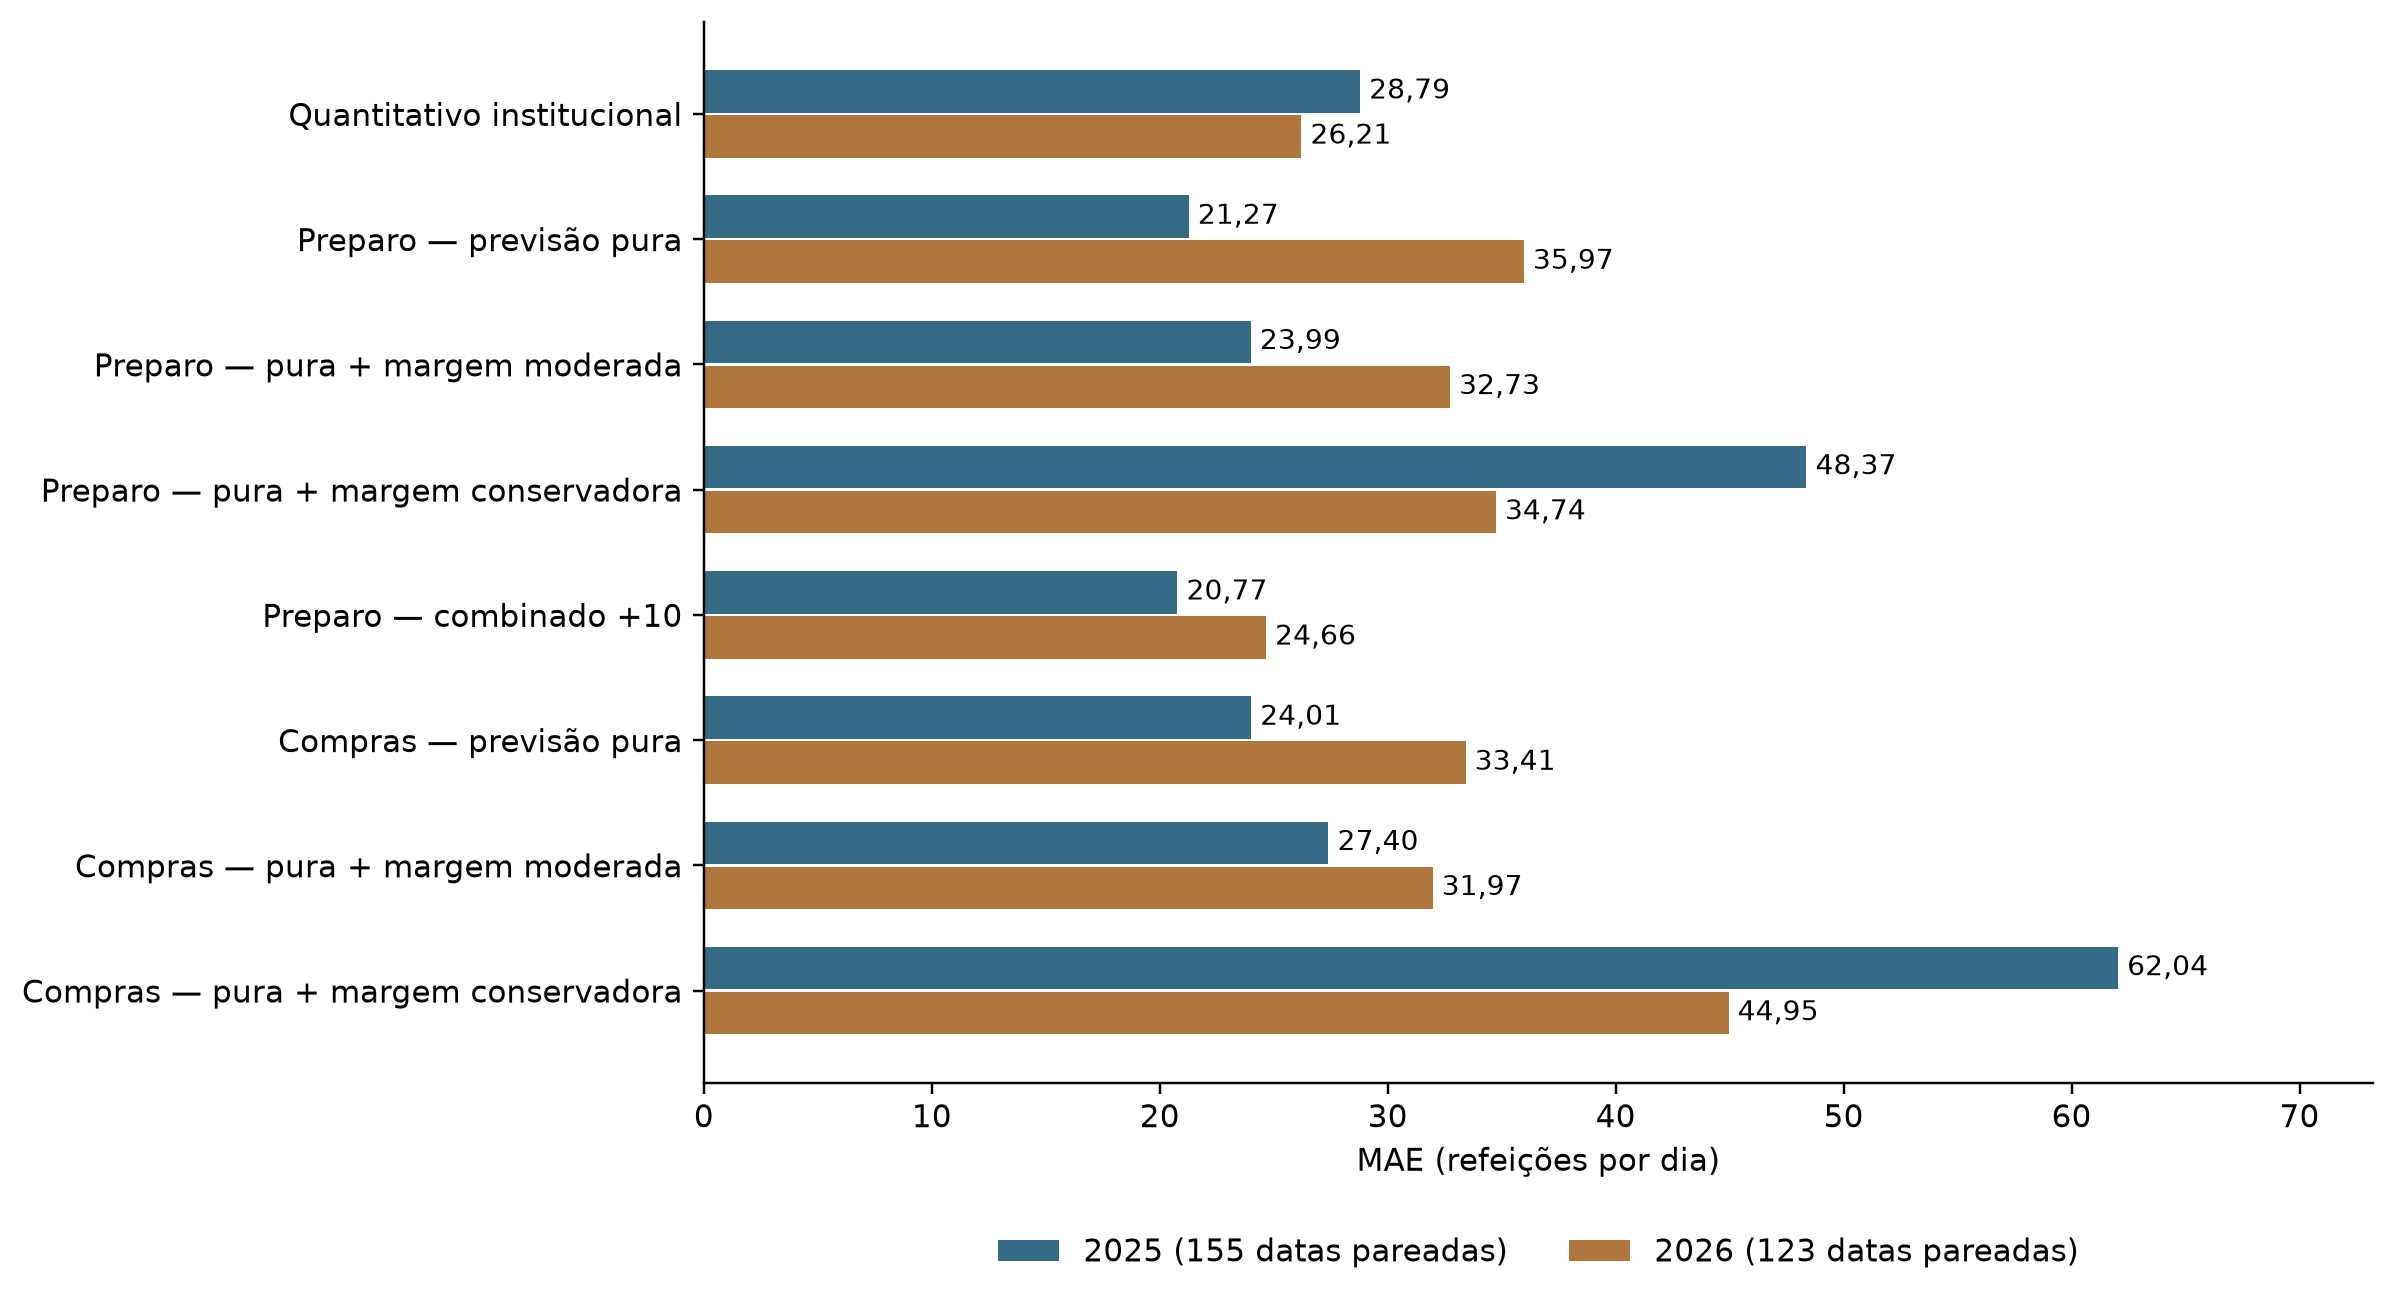

In [7]:
display(pd.read_csv(ROTINA/"metricas_margens_duas_janelas.csv").query("ano in [2025,2026]").round(2))
display(Image(filename=str(ROTINA/"figuras/margens_duas_janelas_2025_2026.png")))